<div dir="rtl">

# הניתוח

המחברת עונה על שאלת המחקר מתוך שלושת הקבצים שמחברת 02 בנתה. כל מבחן וכל תרשים שבספר מחושבים כאן, וכך גם רוב המספרים שפרק המתודולוגיה מצטט. העובדות על הנתונים הגולמיים מחושבות במחברת 01, והאוכלוסיות במחברת 02.

**הקלט.** שלושת הקבצים שבתיקייה `data/clean`, ועוד טבלה אחת מהנתונים הגולמיים: טבלת הלידים, לסך הלידים, משום ש-60 לידים ללא מקור אינם משויכים לאף ערוץ בקבצים המעובדים. טביעת האצבע של הנתונים הגולמיים נבדקת בתחילת המחברת ובסופה.

**הפלט.** תרשימים לתיקייה `book/figures`, ותוצאות שמודפסות כאן. המחברת אינה כותבת שום קובץ נתונים.

**משפחת ההשוואות.** ההשוואות בין ערוצים נערכות בין חמשת ערוצי השיווק המזוהים: חיפוש ממומן, חיפוש אורגני, תנועה ישירה, רשתות חברתיות והפניות. הקטגוריה הלא ידועה וקבוצת הערוצים הקטנים אינן ערוצים שאפשר לרכוש מהם עוד לידים, ולכן הן מוצגות בתרשימים אך אינן נכללות במבחנים הראשיים. השפעת הכללתן מדווחת בנספח ב.

</div>


<div dir="rtl">

## ייבוא, קבועים ובדיקות קלט

</div>


In [1]:
import hashlib, itertools, textwrap
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ft2font
import matplotlib.ticker
from IPython.display import display
from pathlib import Path
from scipy import stats

# Hebrew is laid out by matplotlib itself (libraqm + SheenBidi, bundled since 3.11).
# Raw Hebrew strings render correctly; pre-reversing them with python-bidi would double-reverse.
assert hasattr(matplotlib.ft2font, "__libraqm_version__"), \
    "Hebrew chart text needs matplotlib >= 3.11 (libraqm). Reinstall from requirements.txt."

SEED       = 42
WINDOW     = 90
K_SHRINK   = 5       # review shrinkage strength, as in notebook 02
MIN_SCORED = 20      # a channel enters the value-score test with at least this many scored sellers
Z          = 1.96    # pinned: final_channels.csv was built with exactly 1.96
RAW, CLEAN = Path("..") / "data" / "raw", Path("..") / "data" / "clean"
FIG = Path("..") / "book" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# The five identifiable marketing channels form every comparison family in this notebook.
CHANNELS     = ["paid_search", "organic_search", "direct_traffic", "social", "referral"]
NON_CHANNELS = ["unknown", "small_channels_merged"]      # shown, not compared
HE = {
    "paid_search": "חיפוש ממומן",       "organic_search": "חיפוש אורגני",
    "direct_traffic": "תנועה ישירה",    "social": "רשתות חברתיות",
    "referral": "הפניות",               "unknown": "תנועה לא מיוחסת",
    "small_channels_merged": "ערוצים קטנים (מאוחדים)", "other_publicities": "פרסומים אחרים",
}

# colour marks the pair with the largest activation gap; every other channel is grey
C_PAID, C_ORG, C_GREY, C_INK, C_MUTED = "#2E6FBF", "#D9822B", "#BDBDBD", "#222222", "#6B6B6B"
C_ACCENT = "#37474F"   # emphasis for data that is not a channel, so blue and orange always mean the two channels
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11, "axes.titlesize": 13,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110,
    "savefig.dpi": 150, "savefig.bbox": "tight",
})

def title(ax, main, sub=None, width=66, sub_width=None):
    """Right-aligned Hebrew title and optional subtitle. Titles end on a Hebrew word."""
    ax.set_title(textwrap.fill(main, width), loc="right", fontweight="bold", pad=34 if sub else 12)
    if sub:
        ax.text(1.0, 1.02, balanced(sub, sub_width or width + 14), transform=ax.transAxes,
                ha="right", va="bottom", fontsize=10, color=C_MUTED)

def balanced(text, width):
    """Wrap to the fewest lines that fit, with lines of similar length, so no line is a lone word."""
    lines = textwrap.wrap(text, width)
    if len(lines) < 2:
        return text
    w = len(text) // len(lines) + 1
    while len(textwrap.wrap(text, w)) > len(lines):
        w += 1
    return "\n".join(textwrap.wrap(text, w))

def footnote(fig, text, width=120, y=-0.06):
    fig.text(0.99, y, balanced(text, width), ha="right", va="top", fontsize=8.5, color=C_MUTED)

def save(fig, name):
    fig.savefig(FIG / name); plt.show()

def raw_fingerprint():
    h = hashlib.sha256()
    for p in sorted(RAW.glob("*.csv")):
        h.update(hashlib.sha256(p.read_bytes()).hexdigest().encode())
    return h.hexdigest()

def wilson(k, n, z=Z):
    if n == 0:
        return (np.nan, np.nan)
    p, d = k / n, 1 + z**2 / n
    c, h = (p + z**2 / (2*n)) / d, z * np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / d
    return (max(0.0, c - h), min(1.0, c + h))

FINGERPRINT_BEFORE = raw_fingerprint()

deals   = pd.read_csv(CLEAN / "final_deals.csv", parse_dates=["won_day", "first_sale_date"])
sellers = pd.read_csv(CLEAN / "final_sellers.csv")
ch      = pd.read_csv(CLEAN / "final_channels.csv").set_index("channel")
LEADS_TOTAL = len(pd.read_csv(RAW / "olist_marketing_qualified_leads_dataset.csv", usecols=["mql_id"]))

# settled facts from notebook 02: assert them, so a stale or damaged input fails loudly
assert (len(deals), len(sellers), len(ch)) == (842, 341, 8)
assert LEADS_TOTAL == 8_000 and ch.leads.sum() == 7_940       # 60 leads carry no origin
assert int(deals.eligible.sum()) == 665 and int((deals.eligible & deals.activated).sum()) == 292
for c, r in ch.iterrows():
    lo, hi = wilson(r.activated_eligible, r.deals_eligible)
    assert abs(lo - r.activation_ci_low) < 1e-12 and abs(hi - r.activation_ci_high) < 1e-12, c

# used by every part: 90-day activation among deals with a full window
eligible = deals[deals.eligible]
act = eligible.groupby("channel").activated.agg(["sum", "size"]).rename(columns={"sum": "k", "size": "n"})
n_deals, n_elig, n_act = len(deals), len(eligible), int(eligible.activated.sum())

print("inputs verified | libraqm", matplotlib.ft2font.__libraqm_version__, "| seed", SEED)


inputs verified | libraqm 0.10.5 | seed 42


<div dir="rtl">

## המשפך: היכן הלידים והמוכרים אובדים

רוב הלידים נושרים לפני החתימה, ובשלב הזה ערוצי השיווק נבדלים זה מזה בבירור בשיעור ההמרה, כפי שמראה המבחן בחלק השלישי. אחרי החתימה השאלה היא כמה מהמוכרים שכבר נחתמו מתחילים למכור.

השלב השלישי אינו נשירה אלא סינון להוגנות: נכללות בו רק עסקאות שהיו להן תשעים ימים מלאים לפני סוף הנתונים, כדי שכל מוכר יקבל אותה הזדמנות.

</div>


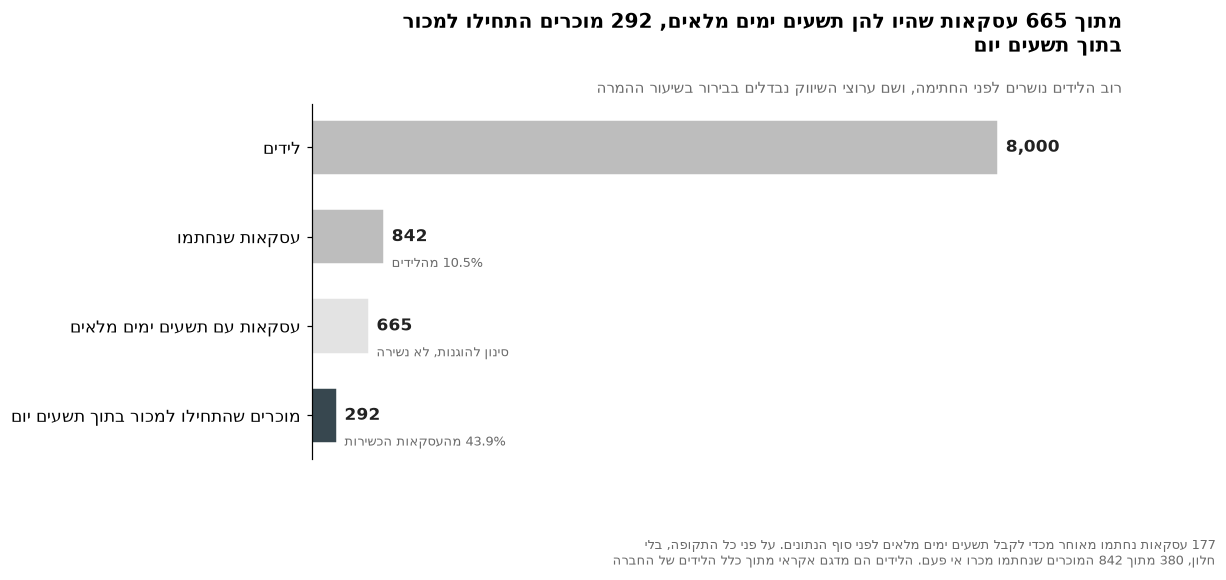

In [2]:
stages = [("לידים", LEADS_TOTAL, None),
          ("עסקאות שנחתמו", n_deals, "%.1f%% מהלידים" % (100*n_deals/LEADS_TOTAL)),
          ("עסקאות עם תשעים ימים מלאים", n_elig, "סינון להוגנות, לא נשירה"),
          ("מוכרים שהתחילו למכור בתוך תשעים יום", n_act, "%.1f%% מהעסקאות הכשירות" % (100*n_act/n_elig))]

fig, ax = plt.subplots(figsize=(9.5, 4.2))
ys = np.arange(len(stages))[::-1]
colours = [C_GREY, C_GREY, "#E3E3E3", C_ACCENT]
for y, (lab, v, note), col in zip(ys, stages, colours):
    ax.barh(y, v, color=col, height=0.62, edgecolor="white")
    ax.text(v + 90, y, "{:,}".format(v), va="center", fontsize=11, fontweight="bold", color=C_INK)
    if note:
        ax.text(v + 90, y - 0.3, note, va="center", fontsize=8.5, color=C_MUTED)
ax.set_yticks(ys, [s[0] for s in stages])
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.set_xlim(0, LEADS_TOTAL * 1.18)
title(ax, "מתוך %d עסקאות שהיו להן תשעים ימים מלאים, %d מוכרים התחילו למכור בתוך תשעים יום" % (n_elig, n_act),
      "רוב הלידים נושרים לפני החתימה, ושם ערוצי השיווק נבדלים בבירור בשיעור ההמרה")
footnote(fig, "%d עסקאות נחתמו מאוחר מכדי לקבל תשעים ימים מלאים לפני סוף הנתונים. על פני כל התקופה, בלי חלון, "
              "%d מתוך %d המוכרים שנחתמו מכרו אי פעם. הלידים הם מדגם אקראי מתוך כלל הלידים של החברה"
         % (n_deals - n_elig, int(deals.first_sale_date.notna().sum()), n_deals))
save(fig, "00_funnel.png")


<div dir="rtl">

# חלק ראשון: כמות מול הפעלה

התרשים מציג את הצד הכמותי של השאלה: כמה לידים כל ערוץ מביא, ואיזה חלק מהמוכרים שלו מתחיל למכור בתוך תשעים יום. **אין בו קו מגמה**, משום ששבע נקודות אינן מספיקות כדי לטעון לקשר בין נפח להפעלה.

</div>


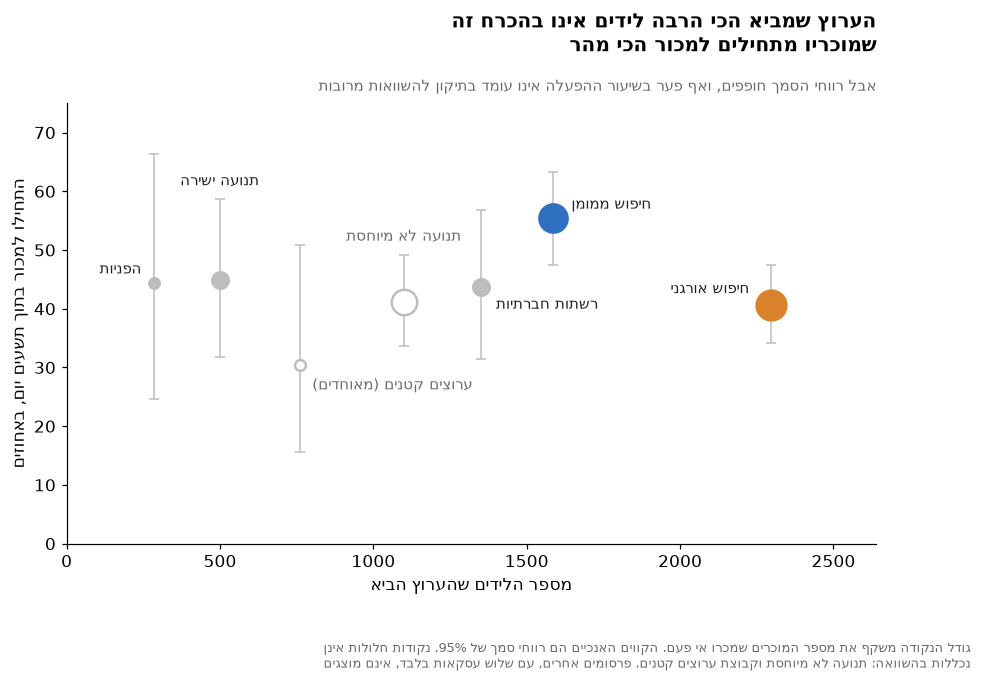

In [3]:
pts = CHANNELS + NON_CHANNELS
# label offsets in points, (dx, dy, ha), placed to keep labels off the error bars
LABEL_POS = {"paid_search": (12, 6, "left"), "organic_search": (-14, 8, "right"), "direct_traffic": (0, 62, "center"),
             "social": (10, -14, "left"), "referral": (-8, 6, "right"),
             "unknown": (0, 40, "center"), "small_channels_merged": (8, -16, "left")}
fig, ax = plt.subplots(figsize=(9.5, 5.2))
for c in pts:
    r = ch.loc[c]
    k, n = act.loc[c]
    rate = k / n
    lo, hi = wilson(k, n)
    col = C_PAID if c == "paid_search" else C_ORG if c == "organic_search" else C_GREY
    hollow = c in NON_CHANNELS
    ax.errorbar(r.leads, 100*rate, yerr=[[100*(rate-lo)], [100*(hi-rate)]], fmt="none", ecolor=C_GREY, lw=1, capsize=3, zorder=1)
    ax.scatter(r.leads, 100*rate, s=18 + 3.2*r.sellers_ever_sold, zorder=2,
               facecolor="white" if hollow else col, edgecolor=C_GREY if hollow else col, linewidth=1.6)
    dx, dy, ha = LABEL_POS[c]
    ax.annotate(HE[c], (r.leads, 100*rate), xytext=(dx, dy), textcoords="offset points", fontsize=9.5,
                ha=ha, color=C_MUTED if hollow else C_INK, zorder=3,
                bbox=dict(facecolor="white", edgecolor="none", pad=0.6, alpha=0.9))
ax.set_xlabel("מספר הלידים שהערוץ הביא")
ax.set_ylabel("התחילו למכור בתוך תשעים יום, באחוזים")
ax.set_ylim(0, 75)
ax.set_xlim(0, ch.leads.max() * 1.15)
title(ax, "הערוץ שמביא הכי הרבה לידים אינו בהכרח זה שמוכריו מתחילים למכור הכי מהר",
      "אבל רווחי הסמך חופפים, ואף פער בשיעור ההפעלה אינו עומד בתיקון להשוואות מרובות", width=42, sub_width=80)
footnote(fig, "גודל הנקודה משקף את מספר המוכרים שמכרו אי פעם. הקווים האנכיים הם רווחי סמך של 95%. "
              "נקודות חלולות אינן נכללות בהשוואה: תנועה לא מיוחסת וקבוצת ערוצים קטנים. פרסומים אחרים, עם שלוש עסקאות בלבד, אינם מוצגים")
save(fig, "01_volume_vs_activation.png")


<div dir="rtl">

## שאלת משנה ראשונה: האם הדירוג לפי כמות שונה מהדירוג לפי הכנסות

הטבלה מדרגת את חמשת הערוצים בשלוש דרכים, ולכל עמודה בסיס משלה: מספר המוכרים שמכרו נספר על כל 842 העסקאות, ההפעלה על העסקאות הכשירות, וחציון ההכנסה על המוכרים שקיבלו ציון. ההכנסה מוצגת כחציון ולא כסכום, משום שסכום היה נשען על מוכר בודד. **אף אחד משלושת הדירוגים אינו נשען על הבדל מובהק**, והמבחנים מופיעים בחלקים השני והשלישי. ההפניות מדורגות ראשונות בהכנסה על סמך תשעה מוכרים בלבד.

</div>


In [4]:
sc = sellers[sellers.channel.isin(CHANNELS)]
rank = pd.DataFrame({
    "ערוץ": [HE[c] for c in CHANNELS],
    "מוכרים שמכרו": [int(ch.loc[c, "sellers_ever_sold"]) for c in CHANNELS],
    "הפעלה בתוך 90 יום, באחוזים": [round(100 * act.loc[c, "k"] / act.loc[c, "n"], 1) for c in CHANNELS],
    "חציון הכנסה בחלון, ריאל": [round(sc[sc.channel == c].revenue_window.median()) for c in CHANNELS],
    "מוכרים שקיבלו ציון": [int(ch.loc[c, "sellers_scored"]) for c in CHANNELS],
})
for col in ["מוכרים שמכרו", "הפעלה בתוך 90 יום, באחוזים", "חציון הכנסה בחלון, ריאל"]:
    rank["מקום: " + col] = rank[col].rank(ascending=False, method="min").astype(int)
display(rank)


,ערוץ,מוכרים שמכרו,"הפעלה בתוך 90 יום, באחוזים","חציון הכנסה בחלון, ריאל",מוכרים שקיבלו ציון,מקום: מוכרים שמכרו,"מקום: הפעלה בתוך 90 יום, באחוזים","מקום: חציון הכנסה בחלון, ריאל"
0,חיפוש ממומן,101,55.5,308,87,2,1,2
1,חיפוש אורגני,113,40.6,225,102,1,5,3
2,תנועה ישירה,31,44.9,147,28,3,2,5
3,רשתות חברתיות,31,43.6,165,26,3,4,4
4,הפניות,9,44.4,512,9,5,3,1


<div dir="rtl">

# חלק שני: האם הערוצים נבדלים באיכות המוכרים

**אילו ערוצים נכנסים לבדיקה.** ערוצי השיווק שיש בהם לפחות עשרים מוכרים שקיבלו ציון. זהו אותו סף של עשרים שקובע אם ערוץ מוצג בשורה נפרדת, אלא שכאן הוא נספר במוכרים ולא בעסקאות. ההפניות, עם תשעה מוכרים, אינן נכנסות. **הבדיקה היא מבחן תמורות:** מחלקים את המוכרים לערוצים באקראי עשרים אלף פעמים, ובודקים באיזה חלק מהחלוקות מתקבל פער גדול לפחות כמו זה שנמצא בפועל.

</div>


In [5]:
TESTED = [c for c in CHANNELS if ch.loc[c, "sellers_scored"] >= MIN_SCORED]
assert TESTED == ["paid_search", "organic_search", "direct_traffic", "social"], TESTED

def perm(df, col, groups, n=20_000, seed=SEED):
    # statistic: highest channel mean minus lowest channel mean; labels are shuffled, values stay
    x = df[df.channel.isin(groups)]
    codes, labels = pd.factorize(x.channel)
    v = x[col].to_numpy()
    counts = np.bincount(codes)
    obs = np.bincount(codes, weights=v) / counts
    gap = obs.max() - obs.min()
    rng = np.random.default_rng(seed)
    null = np.empty(n)
    for i in range(n):
        means = np.bincount(rng.permutation(codes), weights=v) / counts
        null[i] = means.max() - means.min()
    p = (1 + (null >= gap).sum()) / (n + 1)
    return {"n": len(x), "gap": gap, "p": p, "top": labels[obs.argmax()], "bottom": labels[obs.argmin()], "null": null}

COMPONENTS = ["value_score", "revenue_component", "satisfaction_component", "tenure_component"]
P = {col: perm(sellers, col, TESTED) for col in COMPONENTS}
P_unknown = {col: perm(sellers, col, TESTED + ["unknown"]) for col in COMPONENTS}
display(pd.DataFrame({k: {"sellers": v["n"], "gap": round(v["gap"], 3), "p": round(v["p"], 3),
                          "p with unknown": round(P_unknown[k]["p"], 3),
                          "highest": v["top"], "lowest": v["bottom"]} for k, v in P.items()}).T)

top_scores = sellers[sellers.channel == P["value_score"]["top"]].value_score
bottom_scores = sellers[sellers.channel == P["value_score"]["bottom"]].value_score
welch = stats.ttest_ind(top_scores, bottom_scores, equal_var=False)
ci = welch.confidence_interval(0.95)
print("Welch 95%% CI, %s minus %s: %.2f [%.2f, %.2f]  (the pair was chosen as max and min after the fact)"
      % (P["value_score"]["top"], P["value_score"]["bottom"], top_scores.mean() - bottom_scores.mean(), ci.low, ci.high))


,sellers,gap,p,p with unknown,highest,lowest
value_score,243,7.043,0.279,0.301,paid_search,direct_traffic
revenue_component,243,0.099,0.154,0.196,paid_search,direct_traffic
satisfaction_component,243,0.055,0.312,0.463,organic_search,direct_traffic
tenure_component,243,0.107,0.54,0.314,organic_search,direct_traffic


Welch 95% CI, paid_search minus direct_traffic: 7.04 [-0.91, 14.99]  (the pair was chosen as max and min after the fact)


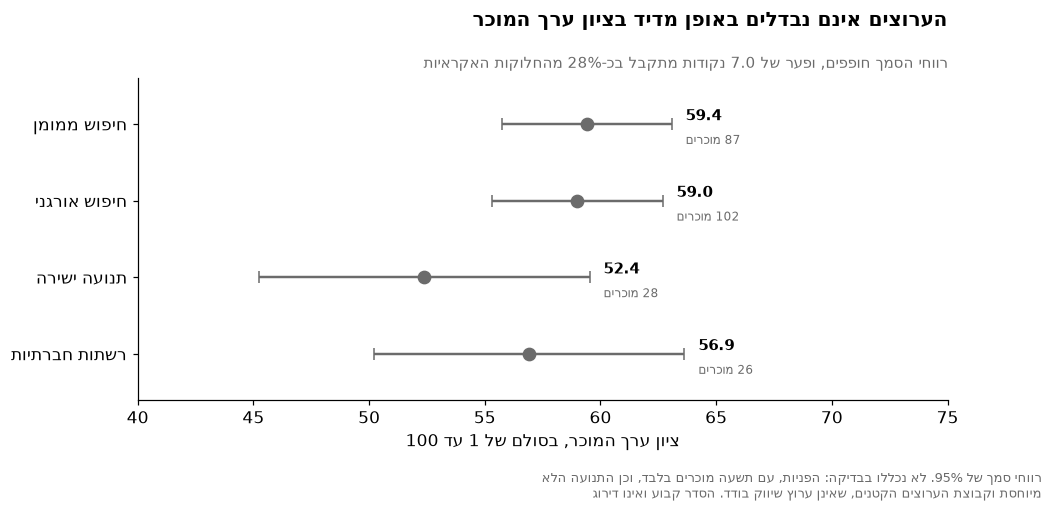

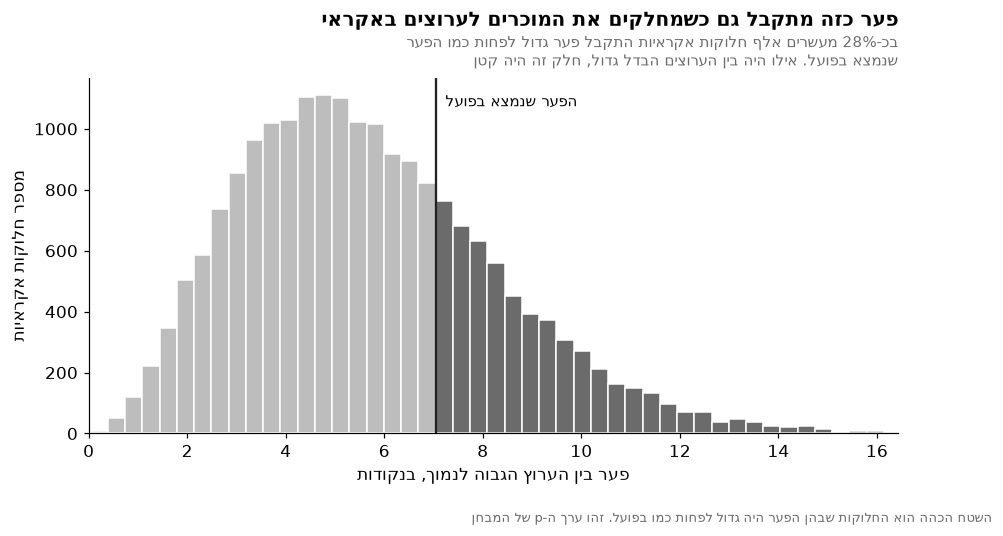

In [6]:
fig, ax = plt.subplots(figsize=(9.5, 3.8))
ys = np.arange(len(TESTED))[::-1]
for yy, c in zip(ys, TESTED):
    r = ch.loc[c]
    ax.errorbar(r.score_mean, yy, xerr=[[r.score_mean - r.score_ci_low], [r.score_ci_high - r.score_mean]],
                fmt="o", color=C_MUTED, ms=8, capsize=4, lw=1.6)
    ax.text(r.score_ci_high + 0.6, yy + 0.1, "%.1f" % r.score_mean, va="center", fontsize=10, fontweight="bold")
    ax.text(r.score_ci_high + 0.6, yy - 0.22, "%d מוכרים" % r.sellers_scored, va="center", fontsize=8, color=C_MUTED)
ax.set_yticks(ys, [HE[c] for c in TESTED])
ax.set_xlim(40, 75)
ax.set_ylim(-0.6, len(TESTED) - 0.4)
ax.set_xlabel("ציון ערך המוכר, בסולם של 1 עד 100")
title(ax, "הערוצים אינם נבדלים באופן מדיד בציון ערך המוכר",
      "רווחי הסמך חופפים, ופער של %.1f נקודות מתקבל בכ-%d%% מהחלוקות האקראיות" % (P["value_score"]["gap"], round(100 * P["value_score"]["p"])))
footnote(fig, "רווחי סמך של 95%. לא נכללו בבדיקה: הפניות, עם תשעה מוכרים בלבד, וכן התנועה הלא מיוחסת וקבוצת הערוצים הקטנים, "
              "שאינן ערוץ שיווק בודד. הסדר קבוע ואינו דירוג")
save(fig, "02a_value_by_channel.png")

null, gap = P["value_score"]["null"], P["value_score"]["gap"]
fig, ax = plt.subplots(figsize=(9.5, 4.2))
bin_w = 0.35
bins = gap + bin_w * np.arange(-int(gap / bin_w) - 1, int((null.max() - gap) / bin_w) + 2)   # an edge sits on the gap
ax.hist(null[null < gap], bins=bins, color=C_GREY, edgecolor="white")
ax.hist(null[null >= gap], bins=bins, color=C_MUTED, edgecolor="white")
ax.axvline(gap, color=C_INK, lw=1.5)
ax.text(gap + 0.2, ax.get_ylim()[1] * 0.92, "הפער שנמצא בפועל", fontsize=9.5)
ax.set_xlabel("פער בין הערוץ הגבוה לנמוך, בנקודות")
ax.set_ylabel("מספר חלוקות אקראיות")
ax.set_xlim(0, np.percentile(null, 99.9) + 0.5)
title(ax, "פער כזה מתקבל גם כשמחלקים את המוכרים לערוצים באקראי",
      "בכ-%.0f%% מעשרים אלף חלוקות אקראיות התקבל פער גדול לפחות כמו הפער שנמצא בפועל. אילו היה בין הערוצים הבדל גדול, "
      "חלק זה היה קטן" % (100 * P["value_score"]["p"]))
footnote(fig, "השטח הכהה הוא החלוקות שבהן הפער היה גדול לפחות כמו בפועל. זהו ערך ה-p של המבחן")
save(fig, "02b_permutation.png")


<div dir="rtl">

## שאלת משנה שנייה: האם מוכר עם הכנסות גבוהות הוא בהכרח מוכר בעל ערך

הערך מורכב מהכנסות, משביעות רצון ומהתמדה. התרשים בודק אם הכנסות גבוהות הולכות יחד עם שני הרכיבים האחרים. **המוכרים שאין להם פעילות בחלון אינם מוצגים**, משום שאין להם ביקורת כלל.

**למה ציון הביקורת המכווץ ולא הממוצע הגולמי.** מוכר עם ביקורת אחת מקבל לעיתים קרובות ממוצע של חמישה כוכבים בדיוק, ומוכרים עם הכנסות נמוכות קיבלו מעט ביקורות. הממוצע הגולמי יוצר לכן קשר שלילי מלאכותי בין הכנסות לשביעות רצון, שנעלם כמעט לגמרי כשמשתמשים בציון המכווץ. התא מחשב את שני המתאמים. הציון המכווץ עדיין נמדד בכוכבים.

</div>


n = 289 | Spearman revenue vs shrunk reviews -0.09 (p 0.14), vs staying power 0.39 (p 3.8e-12) | raw review mean -0.36 (artifact)
perfect 5.0 average: 73% of sellers with one review, 2% of sellers with five or more
top revenue quartile: 73 sellers, 44 of them below the median shrunk review score


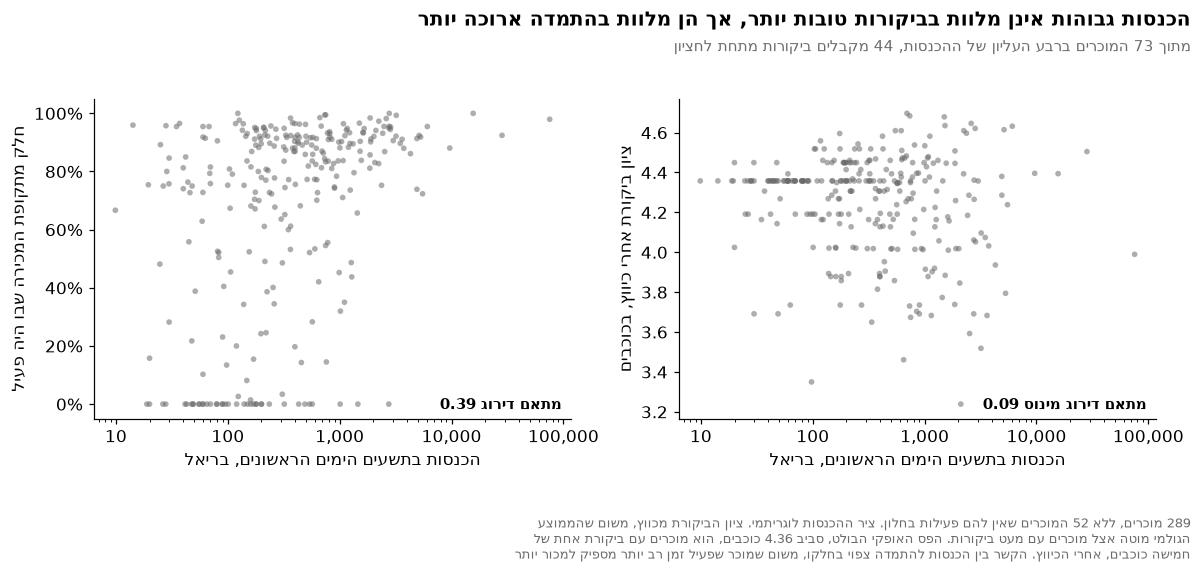

In [7]:
v = sellers[~sellers.no_activity_in_window].copy()
assert len(v) == 289, len(v)
assert v.review_mean.notna().all() and (v.revenue_window > 0).all()
one_review = sellers[sellers.reviews_n == 1]
many_reviews = sellers[sellers.reviews_n >= 5]
share_perfect_one = (one_review.review_mean == 5).mean()
share_perfect_many = (many_reviews.review_mean == 5).mean()
rho_raw = stats.spearmanr(v.revenue_window, v.review_mean).statistic      # small-sample artifact, reported not plotted
sat = stats.spearmanr(v.revenue_window, v.review_shrunk)
ten = stats.spearmanr(v.revenue_window, v.tenure_ratio)
rho_sat, rho_ten = sat.statistic, ten.statistic
top = v.revenue_window >= v.revenue_window.quantile(0.75)
below = int((top & (v.review_shrunk < v.review_shrunk.median())).sum())
print("n = %d | Spearman revenue vs shrunk reviews %.2f (p %.2f), vs staying power %.2f (p %.1e) | raw review mean %.2f (artifact)"
      % (len(v), rho_sat, sat.pvalue, rho_ten, ten.pvalue, rho_raw))
print("perfect 5.0 average: %.0f%% of sellers with one review, %.0f%% of sellers with five or more"
      % (100 * share_perfect_one, 100 * share_perfect_many))
print("top revenue quartile: %d sellers, %d of them below the median shrunk review score" % (int(top.sum()), below))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharex=True)
for ax, col, lab, rho in [(axes[1], "review_shrunk", "ציון ביקורת אחרי כיווץ, בכוכבים", rho_sat),
                          (axes[0], "tenure_ratio", "חלק מתקופת המכירה שבו היה פעיל", rho_ten)]:
    ax.scatter(v.revenue_window, v[col], s=14, color=C_MUTED, alpha=0.55, edgecolor="none")
    ax.set_xscale("log")
    ax.set_xlabel("הכנסות בתשעים הימים הראשונים, בריאל")
    ax.set_ylabel(lab)
    rho_txt = ("מינוס %.2f" % -rho) if rho < 0 else ("%.2f" % rho)
    ax.text(0.98, 0.03, "מתאם דירוג %s" % rho_txt, transform=ax.transAxes, ha="right", fontsize=10, fontweight="bold",
            bbox=dict(facecolor="white", edgecolor="none", pad=2, alpha=0.75))
    ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda x, _: "{:,.0f}".format(x)))
axes[0].yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
fig.tight_layout(rect=(0, 0, 1, 0.84))
fig.text(0.99, 0.985, "הכנסות גבוהות אינן מלוות בביקורות טובות יותר, אך הן מלוות בהתמדה ארוכה יותר",
         ha="right", va="top", fontweight="bold", fontsize=13)
fig.text(0.99, 0.925, "מתוך %d המוכרים ברבע העליון של ההכנסות, %d מקבלים ביקורות מתחת לחציון" % (int(top.sum()), below),
         ha="right", va="top", fontsize=10, color=C_MUTED)
footnote(fig, "%d מוכרים, ללא %d המוכרים שאין להם פעילות בחלון. ציר ההכנסות לוגריתמי. ציון הביקורת מכווץ, משום שהממוצע "
              "הגולמי מוטה אצל מוכרים עם מעט ביקורות. הפס האופקי הבולט, סביב %.2f כוכבים, הוא מוכרים עם ביקורת אחת של חמישה כוכבים, אחרי הכיווץ. "
              "הקשר בין הכנסות להתמדה צפוי בחלקו, משום שמוכר שפעיל זמן רב יותר מספיק למכור יותר"
         % (len(v), int(sellers.no_activity_in_window.sum()), one_review.loc[one_review.review_mean == 5, "review_shrunk"].iloc[0]))
save(fig, "02c_revenue_vs_value.png")


<div dir="rtl">

# חלק שלישי: הפעלה לפי ערוץ

## המבחנים

**המשפחה הראשית** היא עשרת הזוגות שבין חמשת ערוצי השיווק. לצידה מדווחות תמיד שתי חלופות: 15 זוגות, כשהקטגוריה הלא ידועה נכללת, ו-21 זוגות, כשגם קבוצת הערוצים הקטנים נספרת כקבוצה. שלוש שיטות תיקון מוצגות זו לצד זו.

**מבחן נפרד** בודק את שיעור ההמרה מליד לעסקה, כלומר את מה שקורה לפני החתימה. הוא עונה על שאלה אחרת ולכן אינו חלק מהמשפחה. הוא נערך פעמיים: מבחן כולל על חמשת ערוצי השיווק, ומבחן בין החיפוש הממומן לאורגני בלבד.

</div>


In [8]:
def holm(p):
    p = np.asarray(p)
    order, m = np.argsort(p), len(p)
    adj, running = np.empty(m), 0.0
    for i, k in enumerate(order):
        running = max(running, (m - i) * p[k])
        adj[k] = min(1.0, running)
    return adj

def bh(p):
    p = np.asarray(p)
    order, m = np.argsort(p)[::-1], len(p)
    adj, running = np.empty(m), 1.0
    for i, k in enumerate(order):
        running = min(running, p[k] * m / (m - i))
        adj[k] = running
    return adj

def family(groups):
    rows = []
    for a, b in itertools.combinations(groups, 2):
        (ka, na), (kb, nb) = act.loc[a], act.loc[b]
        p = stats.fisher_exact([[ka, na - ka], [kb, nb - kb]])[1]
        rows.append({"pair": "%s vs %s" % (a, b), "rate_a": ka / na, "rate_b": kb / nb, "p_raw": p})
    t = pd.DataFrame(rows)
    t["bonferroni"] = np.minimum(1, t.p_raw * len(t))
    t["holm"] = holm(t.p_raw)
    t["bh"] = bh(t.p_raw)
    return t.sort_values("p_raw").reset_index(drop=True)

FAMILIES = {"10 pairs (primary)": CHANNELS,
            "15 pairs (+ unknown)": CHANNELS + ["unknown"],
            "21 pairs (+ unknown + merged)": CHANNELS + NON_CHANNELS}
fam = {k: family(v) for k, v in FAMILIES.items()}
N_PRIMARY = len(fam["10 pairs (primary)"])

PAIR = "paid_search vs organic_search"
assert all(t.pair[0] == PAIR for t in fam.values()), "the largest activation gap is no longer paid vs organic"
summary = pd.DataFrame({k: t.set_index("pair").loc[PAIR, ["p_raw", "bonferroni", "holm", "bh"]] for k, t in fam.items()}).T
summary["survives (bonferroni)"] = summary.bonferroni < 0.05
summary["pairs surviving (bonferroni)"] = [int((t.bonferroni < 0.05).sum()) for t in fam.values()]
print("paid_search vs organic_search, 90-day activation: %d/%d vs %d/%d" % (*act.loc["paid_search"], *act.loc["organic_search"]))
display(summary.round(4))

omni = {}
for lab, g in [("5 channels (primary)", CHANNELS), ("6 groups (+ unknown)", CHANNELS + ["unknown"])]:
    tab = np.c_[act.loc[g, "k"], act.loc[g, "n"] - act.loc[g, "k"]]
    chi, p, dof, _ = stats.chi2_contingency(tab)
    omni[lab] = p
    print("omnibus chi-square, %-22s chi2 = %.2f, df = %d, p = %.4f" % (lab, chi, dof, p))

pp, oo = ch.loc["paid_search"], ch.loc["organic_search"]
p_conv = stats.fisher_exact([[pp.deals_all, pp.leads - pp.deals_all], [oo.deals_all, oo.leads - oo.deals_all]])[1]
print("\nlead -> deal conversion (separate test): paid %.1f%% vs organic %.1f%%, p = %.3f"
      % (100*pp.deals_all/pp.leads, 100*oo.deals_all/oo.leads, p_conv))
conv_tab = np.c_[ch.loc[CHANNELS, "deals_all"], ch.loc[CHANNELS, "leads"] - ch.loc[CHANNELS, "deals_all"]]
chi_c, p_conv_omni, dof_c, _ = stats.chi2_contingency(conv_tab)
print("lead -> deal conversion, omnibus over the 5 channels: chi2 = %.1f, df = %d, p = %.1e | rates: %s"
      % (chi_c, dof_c, p_conv_omni, ", ".join("%s %.1f%%" % (c, 100*ch.loc[c, "deals_all"]/ch.loc[c, "leads"]) for c in CHANNELS)))


paid_search vs organic_search, 90-day activation: 81/146 vs 84/207


,p_raw,bonferroni,holm,bh,survives (bonferroni),pairs surviving (bonferroni)
10 pairs (primary),0.0068,0.0676,0.0676,0.0676,False,0
15 pairs (+ unknown),0.0068,0.1015,0.1015,0.1015,False,0
21 pairs (+ unknown + merged),0.0068,0.1421,0.1421,0.1421,False,0


omnibus chi-square, 5 channels (primary)   chi2 = 7.89, df = 4, p = 0.0957
omnibus chi-square, 6 groups (+ unknown)   chi2 = 9.06, df = 5, p = 0.1067

lead -> deal conversion (separate test): paid 12.3% vs organic 11.8%, p = 0.651
lead -> deal conversion, omnibus over the 5 channels: chi2 = 46.7, df = 4, p = 1.7e-09 | rates: paid_search 12.3%, organic_search 11.8%, direct_traffic 11.2%, social 5.6%, referral 8.5%


<div dir="rtl">

## התרשים המרכזי: שיעור ההפעלה לפי ערוץ

שני ערוצים צבועים: החיפוש הממומן והחיפוש האורגני, הזוג שהפער ביניהם הוא הגדול ביותר בין ערוצי השיווק. הפער הזה אינו עומד בתיקון להשוואות מרובות, ולכן הצבע מסמן את הזוג שנבדק ולא הבדל שהוכח. שאר הערוצים אפורים. הקטגוריה הלא ידועה וקבוצת הערוצים הקטנים מופיעות מתחת לקו מפריד ובמילוי מקווקו, משום שאינן ערוץ שיווק בודד ואינן נכללות בהשוואה הראשית.

</div>


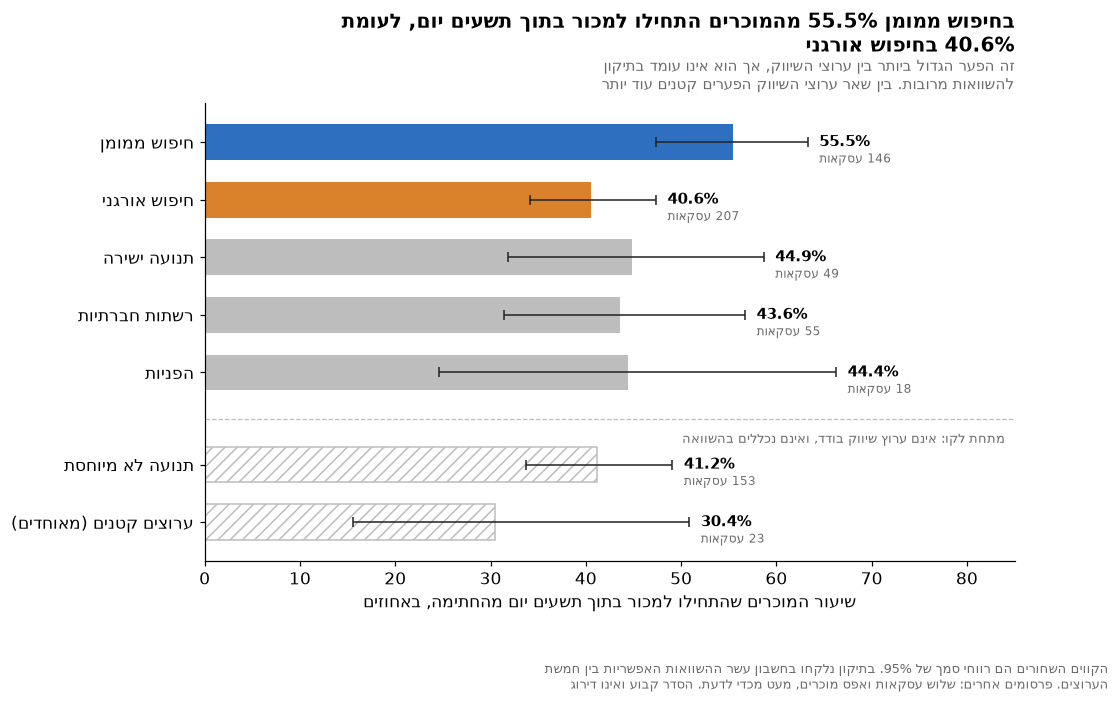

In [9]:
rows = CHANNELS + NON_CHANNELS
y = np.array([len(rows) - i + (0.6 if r in CHANNELS else 0) for i, r in enumerate(rows)])
rate = act.loc[rows, "k"] / act.loc[rows, "n"]
lo = np.array([wilson(*act.loc[r])[0] for r in rows])
hi = np.array([wilson(*act.loc[r])[1] for r in rows])

fig, ax = plt.subplots(figsize=(9.5, 5.4))
for yi, r, v_, l, h in zip(y, rows, rate, lo, hi):
    col = C_PAID if r == "paid_search" else C_ORG if r == "organic_search" else C_GREY
    if r in NON_CHANNELS:
        ax.barh(yi, 100*v_, height=0.62, color="white", edgecolor=C_GREY, hatch="///")
    else:
        ax.barh(yi, 100*v_, height=0.62, color=col)
    ax.errorbar(100*v_, yi, xerr=[[100*(v_-l)], [100*(h-v_)]], fmt="none", ecolor=C_INK, capsize=3, lw=1)
    ax.text(100*h + 1.2, yi, "%.1f%%" % (100*v_), va="center", fontsize=10, fontweight="bold")
    ax.text(100*h + 1.2, yi - 0.3, "%d עסקאות" % act.loc[r, "n"], va="center", fontsize=8, color=C_MUTED)
ax.axhline(y[len(CHANNELS)] + 0.8, color=C_GREY, lw=0.8, ls="--")
ax.text(84, y[len(CHANNELS)] + 0.55, "מתחת לקו: אינם ערוץ שיווק בודד, ואינם נכללים בהשוואה", ha="right", va="top",
        fontsize=8.5, color=C_MUTED)
ax.set_yticks(y, [HE[r] for r in rows])
ax.set_xlim(0, 85)
ax.set_xlabel("שיעור המוכרים שהתחילו למכור בתוך תשעים יום מהחתימה, באחוזים")
title(ax, "בחיפוש ממומן %.1f%% מהמוכרים התחילו למכור בתוך תשעים יום, לעומת %.1f%% בחיפוש אורגני"
      % (100*rate["paid_search"], 100*rate["organic_search"]),
      "זה הפער הגדול ביותר בין ערוצי השיווק, אך הוא אינו עומד בתיקון להשוואות מרובות. בין שאר ערוצי השיווק הפערים קטנים עוד יותר")
footnote(fig, "הקווים השחורים הם רווחי סמך של 95%. בתיקון נלקחו בחשבון עשר ההשוואות האפשריות בין חמשת הערוצים. "
              "פרסומים אחרים: שלוש עסקאות ואפס מוכרים, מעט מכדי לדעת. הסדר קבוע ואינו דירוג")
save(fig, "03a_activation_by_channel.png")


<div dir="rtl">

## סימולציית הסטת המאמץ

**מה מסיטים.** חמישית מהלידים של החיפוש האורגני עוברת לחיפוש הממומן, וסך הלידים נשאר קבוע. זהו זוג ערוצי השיווק שהפער ביניהם הוא הגדול ביותר. מאחר שהפער אינו עומד בתיקון, הסימולציה שואלת כמה הייתה שווה ההסטה **אילו** הפער היה אמיתי, ולכן היא גבול עליון לתועלת ולא תחזית.

**מאיפה באה התוספת.** התא מפרק את התוספת לחלק שנובע מההבדל בשיעור ההמרה ולחלק שנובע מההבדל בשיעור ההפעלה.

**אי הוודאות.** לכל אחד מארבעת השיעורים יש אי ודאות משלו. הסימולציה מגרילה אותם יחד מאה אלף פעמים ומדווחת טווח, ולא מספר בודד.

**הנחות שיש לומר בגלוי.** השיעורים נמדדו בנתונים ולא בניסוי, וההנחה היא שהם נשמרים גם כשמסיטים אליהם לידים. התרחיש הפסימי מכסה רוויה, כלומר לידים נוספים שממירים גרוע יותר, אך לא בחירה עצמית של סוג המוכרים שכל ערוץ מושך. בנוסף, הזוג נבחר משום שהפער שלו הגדול ביותר, ולכן הפער כנראה מעט מנופח.

</div>


moved leads: 459 (20% of organic's 2296) | point estimate 9.33, of it from the activation gap 90% | break-even factor 0.70


,median,low,high,P(gain<=0),"per 1,000 moved leads"
central,9.282,1.922,16.961,0.007,20.213
pessimistic,3.038,-3.482,9.654,0.182,6.616


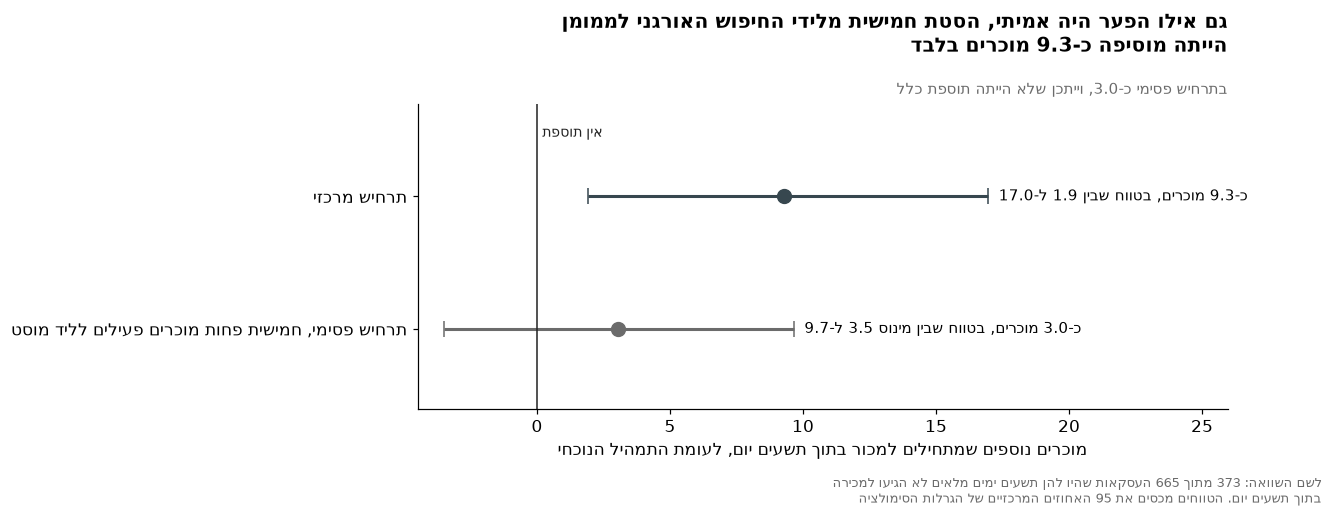

In [10]:
rng = np.random.default_rng(SEED)
N_DRAWS = 100_000
def draw(k, n):                       # Jeffreys posterior for a binomial rate
    return rng.beta(k + 0.5, n - k + 0.5, N_DRAWS)
k_cp, n_cp = int(pp.deals_all), int(pp.leads)
k_co, n_co = int(oo.deals_all), int(oo.leads)
k_ap, n_ap = int(pp.activated_eligible), int(pp.deals_eligible)
k_ao, n_ao = int(oo.activated_eligible), int(oo.deals_eligible)
conv_p, conv_o, act_p, act_o = draw(k_cp, n_cp), draw(k_co, n_co), draw(k_ap, n_ap), draw(k_ao, n_ao)

SHIFT = 0.20
PESSIMISTIC = 0.8                      # moved leads yield a fifth fewer active sellers at the receiving channel
moved = SHIFT * n_co
gain = moved * (conv_p * act_p - conv_o * act_o)
pess = moved * (PESSIMISTIC * conv_p * act_p - conv_o * act_o)
cp_, co_, ap_, ao_ = k_cp/n_cp, k_co/n_co, k_ap/n_ap, k_ao/n_ao
point = moved * (cp_ * ap_ - co_ * ao_)
from_activation = moved * cp_ * (ap_ - ao_)          # the receiving channel's conversion, times the activation gap
breakeven = (co_ * ao_) / (cp_ * ap_)                 # recipient factor at which the gain vanishes

sim = pd.DataFrame({s: {"median": np.median(g), "low": np.percentile(g, 2.5), "high": np.percentile(g, 97.5),
                        "P(gain<=0)": (g <= 0).mean(), "per 1,000 moved leads": 1000*np.median(g)/moved}
                    for s, g in [("central", gain), ("pessimistic", pess)]}).T
print("moved leads: %.0f (%.0f%% of organic's %d) | point estimate %.2f, of it from the activation gap %.0f%% | break-even factor %.2f"
      % (moved, 100*SHIFT, n_co, point, 100 * from_activation / point, breakeven))
display(sim.round(3))

fig, ax = plt.subplots(figsize=(9.5, 3.6))
labels = ["תרחיש מרכזי", "תרחיש פסימי, חמישית פחות מוכרים פעילים לליד מוסט"]
for yi, (s, lab) in enumerate(zip(["central", "pessimistic"], labels)):
    r = sim.loc[s]
    yy = 1 - yi
    ax.errorbar(r["median"], yy, xerr=[[r["median"] - r["low"]], [r["high"] - r["median"]]],
                fmt="o", color=C_ACCENT if s == "central" else C_MUTED, ms=9, capsize=5, lw=2)
    low_txt = ("מינוס %.1f" % -r["low"]) if r["low"] < 0 else ("%.1f" % r["low"])
    ax.text(r["high"] + 0.4, yy, "כ-%.1f מוכרים, בטווח שבין %s ל-%.1f" % (r["median"], low_txt, r["high"]),
            va="center", fontsize=10)
ax.axvline(0, color=C_INK, lw=1)
ax.text(0.2, 1.45, "אין תוספת", fontsize=9, color=C_INK)
ax.set_yticks([1, 0], labels)
ax.set_ylim(-0.6, 1.7)
ax.set_xlim(min(-4, sim["low"].min() - 1), sim["high"].max() + 9)
ax.set_xlabel("מוכרים נוספים שמתחילים למכור בתוך תשעים יום, לעומת התמהיל הנוכחי")
title(ax, "גם אילו הפער היה אמיתי, הסטת חמישית מלידי החיפוש האורגני לממומן הייתה מוסיפה כ-%.1f מוכרים בלבד" % sim.loc["central", "median"],
      "בתרחיש פסימי כ-%.1f, וייתכן שלא הייתה תוספת כלל" % sim.loc["pessimistic", "median"])
footnote(fig, "לשם השוואה: %d מתוך %d העסקאות שהיו להן תשעים ימים מלאים לא הגיעו למכירה בתוך תשעים יום. "
              "הטווחים מכסים את 95 האחוזים המרכזיים של הגרלות הסימולציה" % (n_elig - n_act, n_elig))
save(fig, "03d_simulation.png")


<div dir="rtl">

# מסקנה ותובנה

## מה מצאנו

**לפני החתימה ערוצי השיווק נבדלים בבירור.** רוב הלידים, 7,158 מתוך 8,000, נושרים לפני החתימה, ושיעור ההמרה מליד לעסקה נע בין 5.6 אחוזים ברשתות החברתיות ל-12.3 אחוזים בחיפוש הממומן. זהו ההבדל היחיד בין ערוצים שהוא מובהק בבירור.

**אחרי החתימה, ההבדלים אינם עומדים בתיקון.** בתוך תשעים יום מהחתימה התחילו למכור 55.5 אחוזים מהמוכרים שהגיעו מחיפוש ממומן, לעומת 40.6 אחוזים מאלה שהגיעו מחיפוש אורגני. זהו הפער הגדול ביותר בין ערוצי השיווק, אבל אחרי תיקון לעשר ההשוואות האפשריות הוא אינו מובהק, וגם המבחן הכולל על חמשת הערוצים אינו מובהק. לפני החתימה שני הערוצים האלה כמעט זהים: 12.3 אחוזים מול 11.8 אחוזים.

**בציון ערך המוכר, הערוצים אינם נבדלים באופן מדיד.** פער בגודל שנמצא מתקבל בחלק ניכר מהחלוקות האקראיות, ורווח הסמך שלו כולל גם היעדר הבדל וגם הבדל בינוני.

**הכנסות גבוהות אינן סימן לשביעות רצון גבוהה.** בין הכנסות המוכר לציון הביקורות שלו לא נמצא קשר, אך מוכרים עם הכנסות גבוהות נשארים פעילים זמן רב יותר.

## התובנה

**יותר ממחצית העסקאות שהיו להן תשעים ימים מלאים, 373 מתוך 665, לא הגיעו למכירה בתוך תשעים יום, ו-320 מהן לא הגיעו למכירה כלל עד סוף הנתונים.** אלה מוכרים שכבר עברו את כל שלבי הגיוס והחתימה, והם קיימים בכל הערוצים. בחירת תמהיל ערוצים היא מנוף קטן מולם: גם אילו הפער בין החיפוש הממומן לאורגני היה אמיתי, הסטת חמישית מלידי החיפוש האורגני הייתה מוסיפה כתשעה מוכרים, ובתרחיש פסימי ייתכן שלא הייתה תוספת כלל.

**גבול התובנה.** הנתונים מראים היכן ומתי מוכרים אובדים, אך לא מה יגרום להם להתחיל למכור. כדי לדעת זאת יש לבחון את מה שקורה למוכר בחודשים הראשונים אחרי החתימה, והנתונים האלה אינם במאגר.

## מה נענה ומה לא

| השאלה | התשובה |
|---|---|
| השאלה המרכזית: האם הערוצים שמביאים הכי הרבה מוכרים מביאים גם את הטובים ביותר | לא נמצא הבדל מדיד בין הערוצים באיכות המוכרים, ולכן אי אפשר לומר שערוץ אחד מביא מוכרים טובים יותר |
| האם הדירוג לפי כמות שונה מהדירוג לפי הכנסות | הדירוגים שונים, אך אף אחד מהם אינו נשען על הבדל מובהק, ולכן הם תיאור בלבד |
| האם מוכר עם הכנסות גבוהות הוא בהכרח בעל ערך | לא בהכרח. הכנסות גבוהות אינן מלוות בשביעות רצון גבוהה יותר, אך מלוות בהתמדה ארוכה יותר |
| כמה שווה הסטת מאמץ הגיוס | מעט. גם בהנחה שהפער הגדול ביותר אמיתי, התוספת קטנה מול המוכרים שלא התחילו למכור |

</div>


In [11]:
# Guard: every number quoted in the summary above, recomputed. If data or code change and the prose
# goes stale, this cell fails instead of the summary quietly lying.
r1 = lambda x: round(float(x), 1)
rate_of = lambda c: 100 * act.loc[c, "k"] / act.loc[c, "n"]
conv_rates = 100 * ch.loc[CHANNELS, "deals_all"] / ch.loc[CHANNELS, "leads"]
checks = {
    "leads lost before signing 7,158":  LEADS_TOTAL - n_deals == 7158,
    "conversion range 5.6 to 12.3":     (r1(conv_rates.min()), r1(conv_rates.max()), conv_rates.idxmin(), conv_rates.idxmax()) == (5.6, 12.3, "social", "paid_search"),
    "conversion differs across channels": p_conv_omni < 0.001,
    "conversion organic 11.8, same as paid": r1(100*oo.deals_all/oo.leads) == 11.8 and p_conv > 0.05,
    "activation 55.5 vs 40.6":          (r1(rate_of("paid_search")), r1(rate_of("organic_search"))) == (55.5, 40.6),
    "largest gap does not survive":     not summary.loc["10 pairs (primary)", "survives (bonferroni)"],
    "no pair survives in any family":   not any((t[["bonferroni", "holm", "bh"]] < 0.05).any().any() for t in fam.values()),
    "omnibus not significant":          omni["5 channels (primary)"] > 0.05,
    "value score not significant":      P["value_score"]["p"] > 0.05,
    "value CI straddles zero":          ci.low < 0 < ci.high,
    "revenue vs satisfaction not detectable": sat.pvalue > 0.05,
    "revenue vs staying power positive": rho_ten > 0.3 and ten.pvalue < 0.001,
    "373 of 665 not started":           (n_elig - n_act, n_elig) == (373, 665),
    "320 never sold":                   int(eligible.first_sale_date.isna().sum()) == 320,
    "simulation about nine":            9 <= sim.loc["central", "median"] < 10,
    "pessimistic may be zero":          sim.loc["pessimistic", "low"] < 0,
}
bad = [k for k, ok in checks.items() if not ok]
assert not bad, "summary prose is stale: %s" % bad
print("all %d claims in the summary match the computation" % len(checks))


all 16 claims in the summary match the computation


<div dir="rtl">

# נספח

החומר כאן תומך במסקנות ואינו הכרחי כדי להבין אותן: הצדקת חלון תשעים הימים, כל ההשוואות הזוגיות, חלונות ארוכים יותר, ההתפלגויות, בדיקות הרגישות, ומספרי המתודולוגיה שהספר מצטט.

## נספח א: למה חלון של תשעים יום

העמודות מראות כמה מהמוכרים מכרו אי פעם, לפי חודש החתימה. השיעור צונח מיוני 2018 ואילך, משום שלמוכרים שחתמו מאוחר לא היה זמן למכור לפני שהנתונים נגמרים. הנקודות מראות את שיעור ההפעלה בתוך תשעים יום, רק לחודשים שכל העסקאות בהם היו כשירות: הוא נשאר בין 40 ל-52 אחוזים, בלי מגמה של ירידה, וזה מה שהחלון מתקן.

</div>


,n,ever,n_elig,act90
bucket,,,,
2017-12,3,33.3,3.0,33.3
2018-01,73,56.2,73.0,43.8
2018-02,113,54.0,113.0,39.8
2018-03,147,50.3,147.0,42.2
2018-04,207,50.2,207.0,43.0
2018-05,122,52.5,122.0,51.6
2018-06,57,40.4,NaN,NaN
2018-07,37,27.0,NaN,NaN
2018-08,33,6.1,NaN,NaN


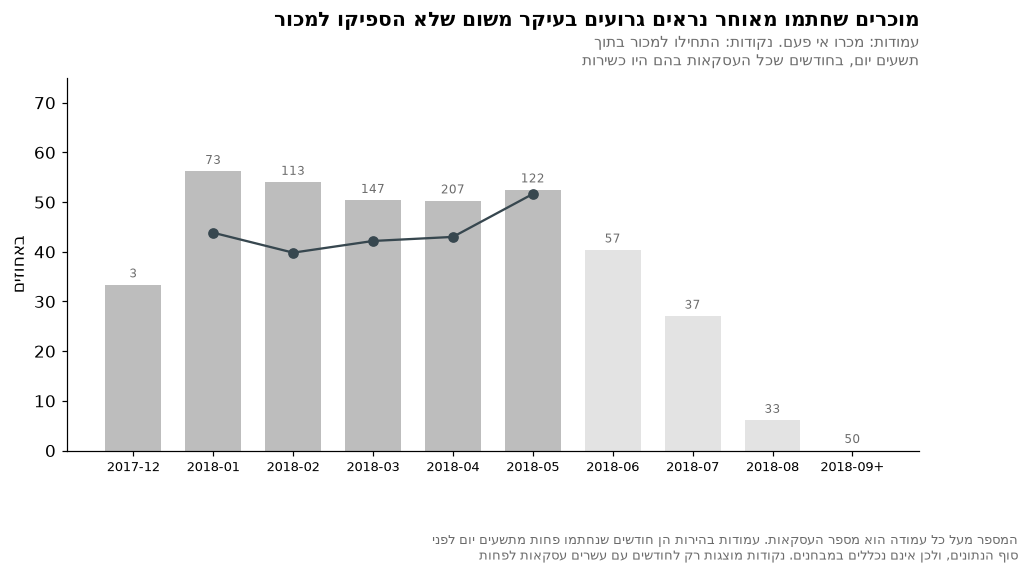

90-day activation in fully eligible months, 20+ deals: 39.8% to 51.6%


In [12]:
dm = deals.assign(month=deals.won_day.dt.to_period("M"))
late = dm.month >= pd.Period("2018-09", "M")
dm["bucket"] = dm.month.astype(str).where(~late, "2018-09+")
g = dm.groupby("bucket").agg(n=("mql_id", "size"), ever=("first_sale_date", lambda s: s.notna().mean()))
ge = dm[dm.eligible].groupby("bucket").agg(n_elig=("mql_id", "size"), act90=("activated", "mean"))
g = g.join(ge)
display(g.assign(ever=(100*g.ever).round(1), act90=(100*g.act90).round(1)))

fig, ax = plt.subplots(figsize=(10, 4.4))
x = np.arange(len(g))
full = (g.n_elig == g.n).to_numpy()                          # months whose every deal had a full window
ax.bar(x, 100 * g.ever, color=[C_GREY if f else "#E3E3E3" for f in full], width=0.7)
for xi, (b, r) in zip(x, g.iterrows()):
    ax.text(xi, 100 * r.ever + 1.5, "%d" % r.n, ha="center", fontsize=8, color=C_MUTED)
shown = full & (g.n >= 20).to_numpy()
ax.plot(x[shown], 100 * g.act90[shown], "o-", color=C_ACCENT, lw=1.5, ms=6)
ax.set_xticks(x, g.index, rotation=0, fontsize=8.5)
ax.set_ylim(0, 75)
ax.set_ylabel("באחוזים")
title(ax, "מוכרים שחתמו מאוחר נראים גרועים בעיקר משום שלא הספיקו למכור",
      "עמודות: מכרו אי פעם. נקודות: התחילו למכור בתוך תשעים יום, בחודשים שכל העסקאות בהם היו כשירות")
footnote(fig, "המספר מעל כל עמודה הוא מספר העסקאות. עמודות בהירות הן חודשים שנחתמו פחות מתשעים יום לפני סוף הנתונים, "
              "ולכן אינם נכללים במבחנים. נקודות מוצגות רק לחודשים עם עשרים עסקאות לפחות")
save(fig, "A1_activation_by_month.png")
print("90-day activation in fully eligible months, %d+ deals: %.1f%% to %.1f%%"
      % (20, 100 * g.act90[shown].min(), 100 * g.act90[shown].max()))


<div dir="rtl">

## נספח ב: כל ההשוואות הזוגיות, בשלוש משפחות

בכל משפחה, השורה הראשונה היא החיפוש הממומן מול האורגני. אף זוג אינו עומד בתיקון באף אחת מהמשפחות.

</div>


In [13]:
for k, t in fam.items():
    print("\n" + k)
    display(t.round(4))



10 pairs (primary)


,pair,rate_a,rate_b,p_raw,bonferroni,holm,bh
0,paid_search vs organic_search,0.5548,0.4058,0.0068,0.0676,0.0676,0.0676
1,paid_search vs social,0.5548,0.4364,0.1552,1.0000,1.0000,0.7758
2,paid_search vs direct_traffic,0.5548,0.4490,0.2472,1.0000,1.0000,0.8241
3,paid_search vs referral,0.5548,0.4444,0.4551,1.0000,1.0000,1.0000
4,organic_search vs direct_traffic,0.4058,0.4490,0.6298,1.0000,1.0000,1.0000
5,organic_search vs social,0.4058,0.4364,0.7583,1.0000,1.0000,1.0000
6,organic_search vs referral,0.4058,0.4444,0.8052,1.0000,1.0000,1.0000
7,direct_traffic vs social,0.4490,0.4364,1.0000,1.0000,1.0000,1.0000
8,direct_traffic vs referral,0.4490,0.4444,1.0000,1.0000,1.0000,1.0000
9,social vs referral,0.4364,0.4444,1.0000,1.0000,1.0000,1.0000



15 pairs (+ unknown)


,pair,rate_a,rate_b,p_raw,bonferroni,holm,bh
0,paid_search vs organic_search,0.5548,0.4058,0.0068,0.1015,0.1015,0.1015
1,paid_search vs unknown,0.5548,0.4118,0.0152,0.2277,0.2125,0.1138
2,paid_search vs social,0.5548,0.4364,0.1552,1.0000,1.0000,0.7758
3,paid_search vs direct_traffic,0.5548,0.4490,0.2472,1.0000,1.0000,0.9271
4,paid_search vs referral,0.5548,0.4444,0.4551,1.0000,1.0000,1.0000
5,organic_search vs direct_traffic,0.4058,0.4490,0.6298,1.0000,1.0000,1.0000
6,direct_traffic vs unknown,0.4490,0.4118,0.7398,1.0000,1.0000,1.0000
7,social vs unknown,0.4364,0.4118,0.7528,1.0000,1.0000,1.0000
8,organic_search vs social,0.4058,0.4364,0.7583,1.0000,1.0000,1.0000
9,referral vs unknown,0.4444,0.4118,0.8050,1.0000,1.0000,1.0000



21 pairs (+ unknown + merged)


,pair,rate_a,rate_b,p_raw,bonferroni,holm,bh
0,paid_search vs organic_search,0.5548,0.4058,0.0068,0.1421,0.1421,0.1421
1,paid_search vs unknown,0.5548,0.4118,0.0152,0.3187,0.3035,0.1594
2,paid_search vs small_channels_merged,0.5548,0.3043,0.0415,0.8721,0.7890,0.2907
3,paid_search vs social,0.5548,0.4364,0.1552,1.0000,1.0000,0.8146
4,paid_search vs direct_traffic,0.5548,0.4490,0.2472,1.0000,1.0000,0.8843
5,direct_traffic vs small_channels_merged,0.4490,0.3043,0.3070,1.0000,1.0000,0.8843
6,social vs small_channels_merged,0.4364,0.3043,0.3194,1.0000,1.0000,0.8843
7,unknown vs small_channels_merged,0.4118,0.3043,0.3691,1.0000,1.0000,0.8843
8,organic_search vs small_channels_merged,0.4058,0.3043,0.3790,1.0000,1.0000,0.8843
9,paid_search vs referral,0.5548,0.4444,0.4551,1.0000,1.0000,0.9557


<div dir="rtl">

## נספח ג: חלונות ארוכים יותר

הכיוון נשמר בכל החלונות: שיעור גבוה יותר מהמוכרים של החיפוש הממומן מתחיל למכור. באף אחד מהחלונות הפער אינו עומד בתיקון.

</div>


In [14]:
rows = []
for lab, W, rule in [("90 days (primary)", 90, "window"), ("120 days", 120, "window"), ("ever sold", None, "ever")]:
    el = deals[deals.exposure_days >= (W or WINDOW)]
    ok = el.first_sale_date.notna() if rule == "ever" else \
         el.first_sale_date.notna() & (el.days_to_first_sale >= 0) & (el.days_to_first_sale <= W)
    tt = el.assign(a=ok).groupby("channel").a.agg(["sum", "size"])
    (kp, np_), (ko, no) = tt.loc["paid_search"], tt.loc["organic_search"]
    p = stats.fisher_exact([[kp, np_ - kp], [ko, no - ko]])[1]
    rows.append({"window": lab, "eligible deals": len(el), "paid %": round(100*kp/np_, 1), "organic %": round(100*ko/no, 1),
                 "gap": round(100*(kp/np_ - ko/no), 1), "raw p": round(p, 4),
                 "adjusted (10 pairs)": round(min(1, N_PRIMARY*p), 3), "survives": N_PRIMARY*p < 0.05})
windows = pd.DataFrame(rows)
display(windows)


,window,eligible deals,paid %,organic %,gap,raw p,adjusted (10 pairs),survives
0,90 days (primary),665,55.5,40.6,14.9,0.0068,0.068,False
1,120 days,543,58.0,45.7,12.3,0.0437,0.437,False
2,ever sold,665,60.3,50.2,10.0,0.0660,0.660,False


<div dir="rtl">

## נספח ד: התפלגות הציון ורכיביו

שלושת הרכיבים מוצגים על אותו סולם כדי שההשוואה ביניהם תהיה הוגנת.

</div>


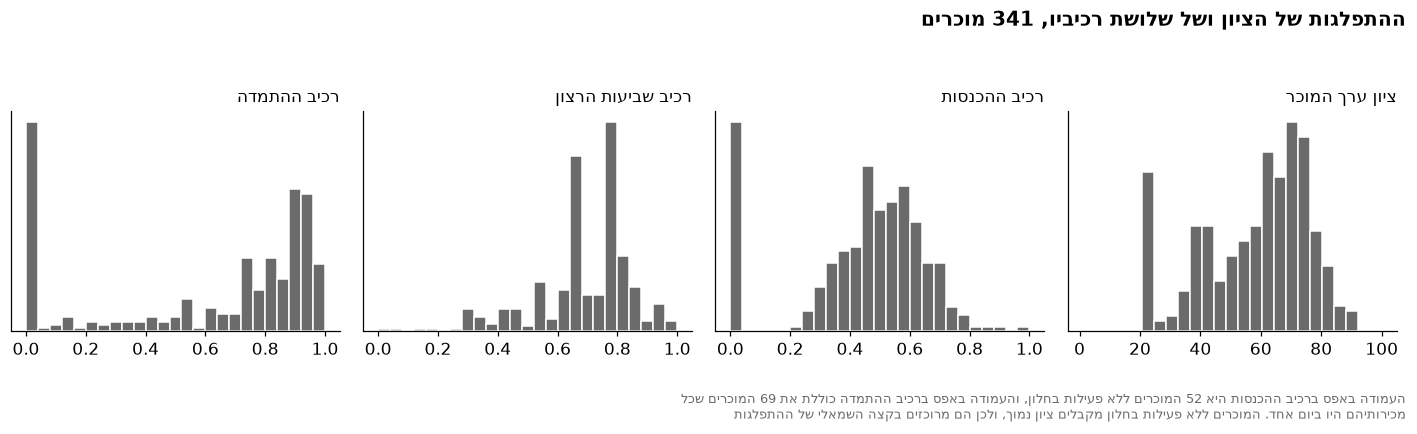

no activity in window: 52 | zero span: 69 | median score of the no-activity sellers: 23.4


In [15]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
cols = [("value_score", "ציון ערך המוכר", (1, 100)), ("revenue_component", "רכיב ההכנסות", (0, 1)),
        ("satisfaction_component", "רכיב שביעות הרצון", (0, 1)), ("tenure_component", "רכיב ההתמדה", (0, 1))]
for ax, (c, lab, rng_) in zip(axes[::-1], cols):
    ax.hist(sellers[c], bins=25, range=rng_, color=C_MUTED, edgecolor="white")
    ax.set_title(lab, fontsize=11, loc="right")
    ax.set_yticks([])
fig.suptitle("ההתפלגות של הציון ושל שלושת רכיביו, %d מוכרים" % len(sellers), x=0.99, ha="right", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.92))
n_none = int(sellers.no_activity_in_window.sum())
n_zero_span = int((sellers.active_span_days == 0).sum())
footnote(fig, "העמודה באפס ברכיב ההכנסות היא %d המוכרים ללא פעילות בחלון, והעמודה באפס ברכיב ההתמדה כוללת את %d המוכרים "
              "שכל מכירותיהם היו ביום אחד. המוכרים ללא פעילות בחלון מקבלים ציון נמוך, ולכן הם מרוכזים בקצה השמאלי של ההתפלגות"
         % (n_none, n_zero_span), y=-0.04)
save(fig, "A4_distributions.png")
print("no activity in window: %d | zero span: %d | median score of the no-activity sellers: %.1f"
      % (n_none, n_zero_span, sellers[sellers.no_activity_in_window].value_score.median()))


<div dir="rtl">

## נספח ה: רגישות למשקלות ולעוצמת הכיווץ

**משקלות.** חמש מאות הגרלות אקראיות של שלושת המשקלות. הטבלה מראה באיזה מקום כל ערוץ נוחת. חוסר יציבות כאן עולה בקנה אחד עם תוצאת מבחן התמורות, אך אינו ראיה נוספת לה, משום ששתי הבדיקות מחושבות מאותם ציונים.

**כיווץ.** מלבד המשקלות, עוצמת הכיווץ של הביקורות היא הפרמטר החופשי היחיד בציון. הטבלה מחשבת את הציון מחדש בשלוש עוצמות.

</div>


In [16]:
WEIGHTED = ["revenue_component", "satisfaction_component", "tenure_component"]
sub = sellers[sellers.channel.isin(TESTED)]
rng = np.random.default_rng(SEED)
weight_draws = rng.dirichlet([1, 1, 1], 500)
places = {c: [] for c in TESTED}
for wts in weight_draws:
    means = (sub[WEIGHTED].to_numpy() @ wts).round(12)
    order = pd.Series(means).groupby(sub.channel.to_numpy()).mean().rank(ascending=False)
    for c in TESTED:
        places[c].append(int(order[c]))
display(pd.DataFrame({HE[c]: pd.Series(places[c]).value_counts().reindex(range(1, len(TESTED) + 1), fill_value=0)
                      for c in TESTED}).rename_axis("מקום"))

# the shrinkage target is not stored; back it out of every seller's shrunk score and take the median
G = ((sellers.review_shrunk * (sellers.reviews_n + K_SHRINK) - sellers.reviews_n * sellers.review_mean.fillna(0)) / K_SHRINK).median()
scale = lambda s: (s - s.min()) / (s.max() - s.min()) if s.max() > s.min() else s * 0
krows = []
for k in [2, K_SHRINK, 10]:
    shrunk = (sellers.reviews_n * sellers.review_mean.fillna(0) + k * G) / (sellers.reviews_n + k)
    score = 1 + 99 * (sellers.revenue_component + scale(shrunk) + sellers.tenure_component) / 3
    m = pd.Series(score.values, index=sellers.channel).loc[lambda s: s.index.isin(TESTED)].groupby(level=0).mean()
    krows.append({"k": k, "gap": round(m.max() - m.min(), 2), "highest": HE[m.idxmax()], "lowest": HE[m.idxmin()]})
print("shrinkage target recovered from the file: %.6f" % G)
display(pd.DataFrame(krows))


,חיפוש ממומן,חיפוש אורגני,תנועה ישירה,רשתות חברתיות
מקום,,,,
1,256,244,0,0
2,244,166,0,90
3,0,90,0,410
4,0,0,500,0


shrinkage target recovered from the file: 4.229457


,k,gap,highest,lowest
0,2,6.83,חיפוש ממומן,תנועה ישירה
1,5,7.04,חיפוש ממומן,תנועה ישירה
2,10,7.16,חיפוש ממומן,תנועה ישירה


<div dir="rtl">

## נספח ו: מספרי המתודולוגיה

פרק המתודולוגיה בספר מצטט מספרים שמצדיקים את ההחלטות שלו: ריכוז ההכנסות, מיעוט הביקורות, הקשר בין משך הפעילות למועד החתימה, הקשרים בין רכיבי הציון, פירוק השונות, והפרטים על הקטגוריה הלא ידועה ועל ערוצים קטנים. כולם מחושבים בתא שלהלן מהקבצים הסופיים.

</div>


In [17]:
rev_w, rev_all = sellers.revenue_window, sellers.revenue_all_time
signed = pd.to_datetime(sellers.won_day).map(pd.Timestamp.toordinal)
iqr_points = lambda s: 100 * (s.quantile(0.75) - s.quantile(0.25))
linear_rev = (rev_w - rev_w.min()) / (rev_w.max() - rev_w.min())
eligible_ever = eligible.first_sale_date.notna()

figures = {
    "deals signed too late for a full window":       int((~deals.eligible).sum()),
    "  of them signed after the data ends":           int((deals.exposure_days < 0).sum()),
    "eligible deals that ever sold":                   int(eligible_ever.sum()),
    "share of them that started within 90 days, %":   round(100 * n_act / eligible_ever.sum(), 1),
    "started after day 90":                            int((eligible_ever & ~eligible.activated).sum()),
    "  median days to first sale":                     float(eligible.loc[eligible_ever & ~eligible.activated, "days_to_first_sale"].median()),
    "top seller share of in-window revenue, %":       round(100 * rev_w.max() / rev_w.sum(), 1),
    "top 10 share of in-window revenue, %":           round(100 * rev_w.nlargest(10).sum() / rev_w.sum(), 1),
    "skew of in-window revenue":                       round(rev_w.skew(), 1),
    "top seller share of all-time revenue, %":        round(100 * rev_all.max() / rev_all.sum(), 1),
    "revenue left outside the window, %":             round(100 * (1 - rev_w.sum() / rev_all.sum()), 1),
    "middle half of sellers, linear scale, points":   round(iqr_points(linear_rev), 1),
    "middle half of sellers, log scale, points":      round(iqr_points(sellers.revenue_component), 1),
    "sellers with fewer than 5 reviews in window":     int((sellers.reviews_n < 5).sum()),
    "median reviews per seller in window":             float(sellers.reviews_n.median()),
    "sellers with no activity in window":              int(sellers.no_activity_in_window.sum()),
    "sellers with zero active span":                   int((sellers.active_span_days == 0).sum()),
    "  of them with a single order":                   int(((sellers.active_span_days == 0) & (sellers.n_orders == 1)).sum()),
    "raw active span vs signing date, Spearman":       round(sellers.active_span_days.corr(signed, method="spearman"), 2),
    "normalised tenure vs signing date, Spearman":     round(sellers.tenure_ratio.corr(signed, method="spearman"), 2),
    "revenue vs tenure components, Spearman":          round(sellers.revenue_component.corr(sellers.tenure_component, method="spearman"), 2),
    "satisfaction vs revenue component, Spearman":     round(sellers.satisfaction_component.corr(sellers.revenue_component, method="spearman"), 2),
    "satisfaction vs tenure component, Spearman":      round(sellers.satisfaction_component.corr(sellers.tenure_component, method="spearman"), 2),
}
total = sellers[WEIGHTED].sum(axis=1)
for c in WEIGHTED:                                         # each component's share of the score's variance
    figures["variance share, " + c + ", %"] = round(100 * np.cov(sellers[c], total)[0, 1] / total.var())
eigval, eigvec = np.linalg.eigh(sellers[WEIGHTED].corr().to_numpy())       # PCA on the standardised components
pc1 = np.abs(eigvec[:, -1])
for c, w_ in zip(WEIGHTED, pc1 / pc1.sum()):              # first-component loadings, as weights summing to 1
    figures["PCA weight, " + c] = round(w_, 2)

unknown = sellers[sellers.channel == "unknown"]
figures.update({
    "unknown: scored sellers":                         len(unknown),
    "unknown: share of scored sellers, %":            round(100 * len(unknown) / len(sellers), 1),
    "unknown: share of all-time revenue, %":          round(100 * unknown.revenue_all_time.sum() / rev_all.sum(), 1),
    "unknown: top seller share within it, %":         round(100 * unknown.revenue_all_time.max() / unknown.revenue_all_time.sum(), 1),
    "unknown: mean all-time revenue":                  round(unknown.revenue_all_time.mean()),
    "unknown: mean without its top seller":            round(unknown.revenue_all_time.drop(unknown.revenue_all_time.idxmax()).mean()),
})
for c in CHANNELS:
    figures["mean all-time revenue, " + c] = round(sellers.loc[sellers.channel == c, "revenue_all_time"].mean())
    figures["median all-time revenue, " + c] = round(sellers.loc[sellers.channel == c, "revenue_all_time"].median())
# Minimum detectable difference, a pairwise approximation: the smallest gap between the largest and the
# smallest tested channel that a two-sample comparison would find with 80% power (alpha 0.05, two-sided),
# using the average within-channel sd. The permutation test compares four channels at once, so its own
# threshold is higher. It replaces a post-hoc power figure, which would only restate the p-value.
sizes = sellers[sellers.channel.isin(TESTED)].groupby("channel").size()
avg_sd = sellers[sellers.channel.isin(TESTED)].groupby("channel").value_score.std().mean()
mdd = (stats.norm.ppf(0.975) + stats.norm.ppf(0.80)) * avg_sd * np.sqrt(1 / sizes.max() + 1 / sizes.min())
figures["value score: average sd within channels"] = round(avg_sd, 1)
figures["value score: minimum detectable gap (pairwise approximation), points"] = round(mdd, 1)
display(pd.Series(figures, name="value", dtype=object).to_frame())


,value
deals signed too late for a full window,177
of them signed after the data ends,53
eligible deals that ever sold,345
"share of them that started within 90 days, %",84.6
started after day 90,53
median days to first sale,113.0
"top seller share of in-window revenue, %",22.4
"top 10 share of in-window revenue, %",47.7
skew of in-window revenue,14.0
"top seller share of all-time revenue, %",18.2


In [18]:
assert raw_fingerprint() == FINGERPRINT_BEFORE, "data/raw was modified"
print("raw data untouched | figures written:", sorted(p.name for p in FIG.glob("*.png")))


raw data untouched | figures written: ['00_funnel.png', '01_volume_vs_activation.png', '02a_value_by_channel.png', '02b_permutation.png', '02c_revenue_vs_value.png', '03a_activation_by_channel.png', '03d_simulation.png', 'A1_activation_by_month.png', 'A4_distributions.png']
